KdV Delta t=0.20 -- SAME PREVIOUS TRAINING PROTOCOL
DEVICE      : cuda
NPZ_PATH    : /kaggle/input/notebooks/xinyuanli913/kdv-dataset-harder/kdv_icl_dataset_delta020/kdv_icl_eps001_002_c1_2_3_Nop200_Ns100_Nc24_Nf256_Nr100_delta020.npz
SAVE_DIR    : /kaggle/working/kdv_harder_eps_c1_nr100_linear_dt020_larger160_L4_FF320_train140_test60
TRAIN/TEST  : 140/60
K train     : 1..5, one K per optimizer batch
K monitor   : 5

Loaded NEW Delta t=0.20 model-facing data:
  operators       : 200
  pair slots/op   : 100
  row width Nr    : 100
  uc_pairs        : (200, 100, 100)
  uf_pairs        : (200, 100, 100)
  x_shared        : (100,)
  eps range       : 0.010035043582320213 to 0.019968729466199875
  c1 range        : 2.0035815238952637 to 2.9991331100463867
  pair t range    : 0.0 to 1.7999999523162842
  target t range  : 0.20000000298023224 to 2.0
  pairing         : uc_common(t) -> uf_common(t+0.20)
  operator        : fixed (eps,c1)

Operator split:
  train operators : 140
  test operators

/tmp/ipykernel_23/246123678.py:1543: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(



Model:
  row width Nr    : 100
  d_model         : 160
  heads           : 4
  layers          : 4
  FF              : 320
  dropout         : 0.1
  trainable params: 888,100

Optimizer/scheduler:
  total steps : 360000
  warmup steps: 28800
  base LR     : 0.0001
  max LR      : 0.0002
  min LR      : 1e-05

START TRAINING
IMPORTANT CLEAN RULE:
  140 operators -> gradients / normalization / monitor / checkpoint selection
   60 operators -> untouched held-out test set
  NO held-out test metric is computed in this script.
  ONE K per optimizer batch; all B episodes share that K.

=== EPOCH 0 TRAIN-SIDE MONITOR ===
Monitor RelL2%: min=84.184, max=98.114, mean=90.508, median=90.321, std=2.283
Monitor R2    : min=-0.229, max=0.058, mean=-0.064, median=-0.065, std=0.048
Raw uc RelL2% : min=87.945, max=148.276, mean=121.969, median=123.696, std=11.157
epoch 001 | trainLoss(norm) 4.774286e-01 | monitor RelL2 mean 46.3093% | best 46.3093% @ 1 | 65.6s | lr 1.041667e-04
  Monitor RelL2%: min=18

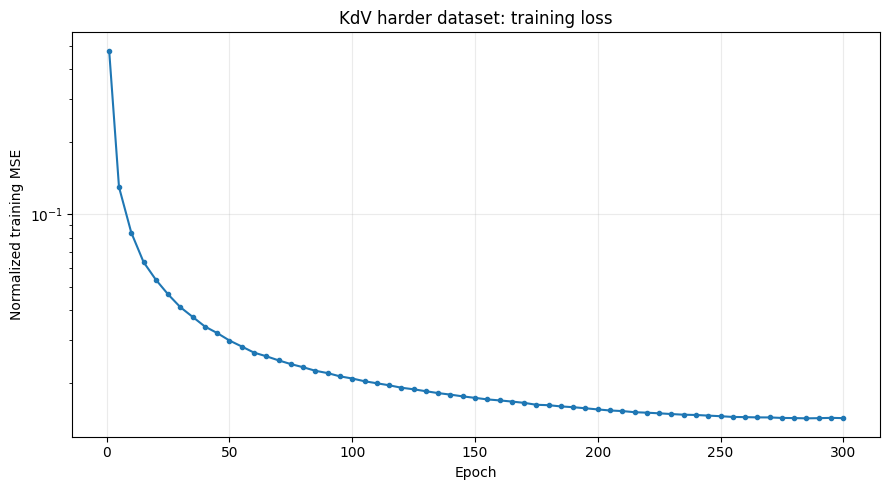

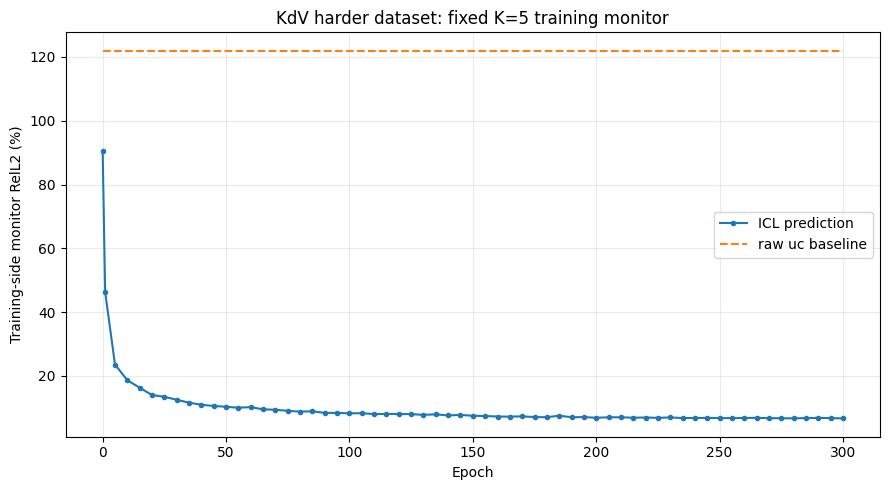


TRAINING COMPLETE
Best epoch: 280
Best TRAIN-SIDE monitor RelL2%: min=2.252, max=16.126, mean=6.678, median=6.003, std=2.564
Best TRAIN-SIDE monitor R2: min=0.968, max=0.999, mean=0.993, median=0.995, std=0.005
Raw uc baseline on same monitor: min=87.945, max=148.276, mean=121.969, median=123.696, std=11.157

IMPORTANT:
  New operator = (eps,c1)
  Delta t = 0.20
  100 valid pair slots/operator
  ONE K per optimizer batch
  Training protocol unchanged; only model capacity increased
  The 60 held-out operators were NOT evaluated.
  They were not used for gradients, normalization, monitoring, or checkpoint selection.
  Next step: separate fixed-K=5 formal evaluation on those 60 unseen operators.

Saved:
 - /kaggle/working/kdv_harder_eps_c1_nr100_linear_dt020_larger160_L4_FF320_train140_test60/kdv_harder_eps_c1_nr100_linear_dt020_larger160_L4_FF320_train140_test60_best_trainmonitor_fullstate.pt
 - /kaggle/working/kdv_harder_eps_c1_nr100_linear_dt020_larger160_L4_FF320_train140_test60/kdv_

In [1]:
# ============================================================
# KAGGLE ONE-CELL:
# KdV ICL TRAINING -- NEW HARDER DATASET, Delta t = 0.20
# 140 TRAIN OPERATORS / 60 HELD-OUT TEST OPERATORS
# SAME ARCHITECTURE + TRAINING PROTOCOL AS PREVIOUS KdV RUN
# ============================================================
#
# IMPORTANT:
# This script intentionally keeps the PREVIOUS KdV training code
# unchanged except where the NEW DATASET requires a change.
#
# WHAT CHANGED
# ------------
# Old operator:
#   (beta, c1)
#
# New operator:
#   (eps, c1)
#
# Old dataset:
#   HDF5 with saved trajectories + pair indices
#
# New dataset:
#   NPZ where uc_common and uf_common are ALREADY the paired data:
#       uc_common[op,j] = uc(x,t_j)
#       uf_common[op,j] = uf(x,t_j+0.20)
#
# WHAT DID NOT CHANGE
# -------------------
#   - fixed random 140/60 operator split, SEED=42
#   - 140 training operators only for:
#       gradients
#       normalization
#       training-side monitor
#       checkpoint selection
#   - 60 held-out operators are NOT evaluated here
#
#   - dynamic K in {1,2,3,4,5}
#   - ONE K sampled per optimizer batch
#   - all B sequences in one batch use the same K
#   - operator sampled independently for each batch element
#   - K demos + 1 query are distinct pair slots
#   - all demos/query in one episode come from the same operator
#
#   - fixed K=5 training-side monitor
#   - no causal mask
#   - direct full uf prediction
#   - final visible row only receives loss
#
# MODEL -- LARGER CAPACITY; ALL OTHER TRAINING PROTOCOL UNCHANGED
# --------------------------------
# row width Nr = 100
# d_model = 160
# heads = 4
# layers = 4
# FF = 320
# dropout = 0.10
# tanh Transformer activation
# norm_first = True
# tanh output MLP
# expected trainable parameters = 888,100
#
# TRAINING -- SAME AS PREVIOUS CODE
# ---------------------------------
# batch = 1000
# epochs = 300
# steps/epoch = 1200
# PRINT_EVERY = 5
#
# AdamW
# weight decay = 1e-4
# LR 1e-4 -> 2e-4 warmup -> cosine -> 1e-5
# warmup fraction = 0.08
# grad clip = 1.0
# FP32 training (no AMP)
#
# NEW DATASET
# -----------
# /kaggle/input/notebooks/xinyuanli913/kdv-dataset-harder/
#   kdv_icl_dataset_delta020/
#   kdv_icl_eps001_002_c1_2_3_Nop200_Ns100_Nc24_Nf256_Nr100_delta020.npz
#
# New PDE family:
#   u_t - eps*u_xxx + (u^2/2)_x = 0
#   eps ~ U[0.01,0.02]
#   c1  ~ U[2,3]
#
# One operator = one fixed (eps,c1)
#
# Native grids:
#   Nc = 24
#   Nf = 256
#
# Shared model grid:
#   Nr = 100
#
# Shared-grid mapping:
#   periodic piecewise-linear interpolation
#
# Paired samples:
#   uc(x,t) -> uf(x,t+0.20)
#
# In this new NPZ:
#   100 valid paired slots/operator
# ============================================================

import time
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn


# ============================================================
# 0. CONFIG
# ============================================================

SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

DATASET_DIR = Path(
    "/kaggle/input/notebooks/xinyuanli913/kdv-dataset-harder/"
    "kdv_icl_dataset_delta020"
)

DATASET_NAME = (
    "kdv_icl_eps001_002_c1_2_3_"
    "Nop200_Ns100_Nc24_Nf256_Nr100_delta020.npz"
)

NPZ_PATH = (
    DATASET_DIR
    / DATASET_NAME
)

RUN_TAG = (
    "kdv_harder_eps_c1_nr100_linear_dt020_"
    "larger160_L4_FF320_train140_test60"
)

SAVE_DIR = (
    Path("/kaggle/working")
    / RUN_TAG
)

SAVE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

# Operator split
N_TRAIN_OP = 140
N_TEST_OP = 60

# ICL
MIN_DEMOS = 1
MAX_DEMOS = 5
TEST_FIXED_DEMOS = 5

# Training -- EXACT SAME VALUES AS PREVIOUS CODE
BATCH_SIZE = 1000
EPOCHS = 300
STEPS_PER_EPOCH = 1200
PRINT_EVERY = 5

# Training-side monitor only
N_MONITOR_CASES = 512
EVAL_BATCH_SIZE = 256

# Optimizer / scheduler -- EXACT SAME
WEIGHT_DECAY = 1e-4
BASE_LR = 1e-4
MAX_LR = 2e-4
MIN_LR = 1e-5
WARMUP_FRAC = 0.08
GRAD_CLIP = 1.0

# Model -- EXACT SAME
D_MODEL = 160
N_HEAD = 4
N_LAYERS = 4
D_FF = 320
DROPOUT = 0.10

EPS_METRIC = 1e-8

# Sequence row types -- EXACT SAME
TYPE_X_DEMO = 0
TYPE_UC_DEMO = 1
TYPE_UF_DEMO = 2
TYPE_X_QUERY = 3
TYPE_UC_QUERY = 4
N_ROW_TYPES = 5

MAX_CTX_ROWS = (
    3 * MAX_DEMOS
    + 2
)

# Reproducibility -- EXACT SAME
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

if DEVICE == "cuda":
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True


# ============================================================
# 1. LOCATE DATASET
# ============================================================

if not NPZ_PATH.exists():

    candidates = (
        sorted(
            DATASET_DIR.rglob("*.npz")
        )
        if DATASET_DIR.exists()
        else []
    )

    if len(candidates) == 1:

        NPZ_PATH = candidates[0]

        print(
            "Recovered NPZ path:",
            NPZ_PATH
        )

    else:

        raise FileNotFoundError(
            f"Expected dataset:\n{NPZ_PATH}\n"
            f"Found {len(candidates)} .npz files "
            f"under {DATASET_DIR}."
        )


print("=" * 112)

print(
    "KdV Delta t=0.20 -- SAME PREVIOUS TRAINING PROTOCOL"
)

print("=" * 112)

print(
    "DEVICE      :",
    DEVICE
)

print(
    "NPZ_PATH    :",
    NPZ_PATH
)

print(
    "SAVE_DIR    :",
    SAVE_DIR
)

print(
    "TRAIN/TEST  :",
    f"{N_TRAIN_OP}/{N_TEST_OP}"
)

print(
    "K train     :",
    f"{MIN_DEMOS}..{MAX_DEMOS}, "
    "one K per optimizer batch"
)

print(
    "K monitor   :",
    TEST_FIXED_DEMOS
)

print("=" * 112)


# ============================================================
# 2. LOAD MODEL-FACING DATASET
# ============================================================
#
# NEW DATASET DIFFERENCE:
# uc_common and uf_common are already the exact paired pool:
#
#   uc_pairs[op,j] = uc(x,t_j)
#   uf_pairs[op,j] = uf(x,t_j+0.20)
#
# Therefore NO pair_coarse_index / pair_fine_index is needed.
# ============================================================

with np.load(
    NPZ_PATH,
    allow_pickle=True,
) as f:

    required = [
        "eps",
        "c1",
        "x_r",
        "t_in",
        "t_out",
        "uc_common",
        "uf_common",
    ]

    for key in required:

        if key not in f:

            raise KeyError(
                f"Missing NPZ dataset: {key}"
            )

    eps_all = (
        f["eps"][:]
        .astype(np.float64)
        .reshape(-1)
    )

    c1_all = (
        f["c1"][:]
        .astype(np.float64)
        .reshape(-1)
    )

    x_grid = (
        f["x_r"][:]
        .astype(np.float32)
        .reshape(-1)
    )

    pair_t = (
        f["t_in"][:]
        .astype(np.float64)
        .reshape(-1)
    )

    pair_t_target = (
        f["t_out"][:]
        .astype(np.float64)
        .reshape(-1)
    )

    # These are already paired:
    # uc_common(op,j) at t_in[j]
    # uf_common(op,j) at t_out[j] = t_in[j] + 0.20
    uc_pairs = (
        f["uc_common"][:]
        .astype(np.float32)
    )

    uf_pairs = (
        f["uf_common"][:]
        .astype(np.float32)
    )

    # Optional metadata
    dataset_metadata = {}

    if "metadata_json" in f:

        try:

            meta_raw = f["metadata_json"]

            if np.ndim(meta_raw) == 0:
                meta_raw = meta_raw.item()

            dataset_metadata = json.loads(
                str(meta_raw)
            )

        except Exception:

            dataset_metadata = {}


# ============================================================
# 2A. INTEGRITY CHECKS
# ============================================================

N_OP, N_PAIR, NX = (
    uc_pairs.shape
)

assert (
    uf_pairs.shape
    == (
        N_OP,
        N_PAIR,
        NX,
    )
)

assert N_OP == 200, N_OP
assert N_PAIR == 100, N_PAIR
assert NX == 100, NX

assert (
    N_TRAIN_OP
    + N_TEST_OP
    == N_OP
)

assert (
    x_grid.shape
    == (
        NX,
    )
)

assert (
    pair_t.shape
    == pair_t_target.shape
    == (
        N_PAIR,
    )
)

assert np.all(
    pair_t_target
    > pair_t
)

assert np.allclose(
    pair_t_target
    - pair_t,
    0.20,
    atol=1e-6,
)

assert np.isclose(
    pair_t[0],
    0.0,
    atol=1e-6,
)

assert np.isclose(
    pair_t_target[0],
    0.20,
    atol=1e-6,
)

assert np.isclose(
    pair_t[-1],
    1.80,
    atol=1e-6,
)

assert np.isclose(
    pair_t_target[-1],
    2.00,
    atol=1e-6,
)

# Final new-family sanity checks
assert len(eps_all) == N_OP
assert len(c1_all) == N_OP

assert eps_all.min() >= 0.01 - 1e-6
assert eps_all.max() <= 0.02 + 1e-6

assert c1_all.min() >= 2.0 - 1e-6
assert c1_all.max() <= 3.0 + 1e-6

assert np.all(
    np.isfinite(
        uc_pairs
    )
)

assert np.all(
    np.isfinite(
        uf_pairs
    )
)


print(
    "\nLoaded NEW Delta t=0.20 model-facing data:"
)

print(
    "  operators       :",
    N_OP
)

print(
    "  pair slots/op   :",
    N_PAIR
)

print(
    "  row width Nr    :",
    NX
)

print(
    "  uc_pairs        :",
    uc_pairs.shape
)

print(
    "  uf_pairs        :",
    uf_pairs.shape
)

print(
    "  x_shared        :",
    x_grid.shape
)

print(
    "  eps range       :",
    float(
        eps_all.min()
    ),
    "to",
    float(
        eps_all.max()
    )
)

print(
    "  c1 range        :",
    float(
        c1_all.min()
    ),
    "to",
    float(
        c1_all.max()
    )
)

print(
    "  pair t range    :",
    float(
        pair_t.min()
    ),
    "to",
    float(
        pair_t.max()
    )
)

print(
    "  target t range  :",
    float(
        pair_t_target.min()
    ),
    "to",
    float(
        pair_t_target.max()
    )
)

print(
    "  pairing         : "
    "uc_common(t) -> uf_common(t+0.20)"
)

print(
    "  operator        : fixed (eps,c1)"
)


# ============================================================
# 3. FIXED 140/60 OPERATOR SPLIT
# ============================================================
#
# EXACT SAME SEED=42 split logic as previous KdV training.
# We intentionally rebuild the split here instead of using the
# generator's saved split, so the training protocol is identical.
# ============================================================

rng_split = (
    np.random.default_rng(
        SEED
    )
)

perm = (
    rng_split.permutation(
        N_OP
    )
)

train_ops = np.sort(
    perm[
        :N_TRAIN_OP
    ]
).astype(
    np.int64
)

test_ops = np.sort(
    perm[
        N_TRAIN_OP:
    ]
).astype(
    np.int64
)

assert len(
    train_ops
) == N_TRAIN_OP

assert len(
    test_ops
) == N_TEST_OP

assert len(
    np.intersect1d(
        train_ops,
        test_ops,
    )
) == 0

assert np.array_equal(
    np.sort(
        np.concatenate(
            [
                train_ops,
                test_ops,
            ]
        )
    ),
    np.arange(
        N_OP
    ),
)


def range_string(
    arr,
    ops,
):
    return (
        f"[{float(arr[ops].min()):.6f}, "
        f"{float(arr[ops].max()):.6f}]"
    )


print(
    "\nOperator split:"
)

print(
    "  train operators :",
    len(
        train_ops
    )
)

print(
    "  test operators  :",
    len(
        test_ops
    )
)

print(
    "  train eps range :",
    range_string(
        eps_all,
        train_ops,
    )
)

print(
    "  test  eps range :",
    range_string(
        eps_all,
        test_ops,
    )
)

print(
    "  train c1 range  :",
    range_string(
        c1_all,
        train_ops,
    )
)

print(
    "  test  c1 range  :",
    range_string(
        c1_all,
        test_ops,
    )
)

print(
    "  overlap IDs     :",
    len(
        np.intersect1d(
            train_ops,
            test_ops,
        )
    )
)


np.savez(
    SAVE_DIR
    / "operator_split.npz",

    train_ops=train_ops,
    test_ops=test_ops,
    eps=eps_all,
    c1=c1_all,
)

split_df = pd.DataFrame({
    "operator":
        np.arange(
            N_OP,
            dtype=np.int64,
        ),

    "eps":
        eps_all,

    "c1":
        c1_all,

    "split":
        np.where(
            np.isin(
                np.arange(
                    N_OP
                ),
                train_ops,
            ),
            "train",
            "test",
        ),
})

split_df.to_csv(
    SAVE_DIR
    / "operator_split.csv",
    index=False,
)


# ============================================================
# 4. TRAIN-ONLY NORMALIZATION
# ============================================================
# EXACT SAME normalization method as previous code.
# ============================================================

uc_train_phys = (
    uc_pairs[
        train_ops
    ]
)

uf_train_phys = (
    uf_pairs[
        train_ops
    ]
)

uc_mean = float(
    uc_train_phys.mean()
)

uc_std = float(
    uc_train_phys.std()
    + 1e-6
)

uf_mean = float(
    uf_train_phys.mean()
)

uf_std = float(
    uf_train_phys.std()
    + 1e-6
)

x_mean = float(
    x_grid.mean()
)

x_std = float(
    x_grid.std()
    + 1e-6
)

x_n = (
    (
        x_grid
        - x_mean
    )
    / x_std
).astype(
    np.float32
)

uc_n = (
    (
        uc_pairs
        - uc_mean
    )
    / uc_std
).astype(
    np.float32
)

uf_n = (
    (
        uf_pairs
        - uf_mean
    )
    / uf_std
).astype(
    np.float32
)


print(
    "\nNormalization -- 140 TRAIN operators only:"
)

print(
    f"  x  mean/std : "
    f"{x_mean:.8f} / {x_std:.8f}"
)

print(
    f"  uc mean/std : "
    f"{uc_mean:.8f} / {uc_std:.8f}"
)

print(
    f"  uf mean/std : "
    f"{uf_mean:.8f} / {uf_std:.8f}"
)


# ============================================================
# 5. TRAIN-SPLIT RAW BASELINE ONLY
# ============================================================
# EXACT SAME metric as previous code.
# ============================================================

def rel_l2_np(
    pred,
    target,
):

    num = np.linalg.norm(
        pred - target,
        axis=-1,
    )

    den = np.linalg.norm(
        target,
        axis=-1,
    )

    return (
        num
        / np.maximum(
            den,
            EPS_METRIC,
        )
    )


train_raw_rel = (
    rel_l2_np(
        uc_pairs[
            train_ops
        ],
        uf_pairs[
            train_ops
        ],
    )
    .reshape(-1)
)


print(
    "\nTraining-split raw uc -> uf baseline:"
)

print(
    f"  mean   : "
    f"{100*np.mean(train_raw_rel):.4f}%"
)

print(
    f"  median : "
    f"{100*np.median(train_raw_rel):.4f}%"
)

print(
    f"  min    : "
    f"{100*np.min(train_raw_rel):.4f}%"
)

print(
    f"  max    : "
    f"{100*np.max(train_raw_rel):.4f}%"
)

print(
    "  NOTE: held-out test baseline is intentionally "
    "not evaluated here."
)


# ============================================================
# 6. FAST BATCH SAMPLING
# ============================================================
# EXACT SAME algorithm as previous code.
# Only N_PAIR changed automatically from 73 -> 100.
# ============================================================

rng_train = (
    np.random.default_rng(
        SEED + 100
    )
)


def sample_distinct_slots(
    rng,
    batch_size,
    n_pick,
    n_slots,
):
    """
    Returns [batch_size, n_pick].
    All selected pair-slot indices are distinct within
    each ICL episode.

    Here:
      n_pick <= 6
      n_slots = 100
    """

    out = rng.integers(
        0,
        n_slots,
        size=(
            batch_size,
            n_pick,
        ),
        dtype=np.int64,
    )

    while True:

        sorted_out = np.sort(
            out,
            axis=1,
        )

        bad = np.any(
            sorted_out[
                :,
                1:
            ]
            ==
            sorted_out[
                :,
                :-1
            ],
            axis=1,
        )

        if not np.any(
            bad
        ):
            break

        n_bad = int(
            np.sum(
                bad
            )
        )

        out[
            bad
        ] = rng.integers(
            0,
            n_slots,
            size=(
                n_bad,
                n_pick,
            ),
            dtype=np.int64,
        )

    return out


def row_types_for_k(
    k
):

    types = []

    for _ in range(
        k
    ):

        types.extend(
            [
                TYPE_X_DEMO,
                TYPE_UC_DEMO,
                TYPE_UF_DEMO,
            ]
        )

    types.extend(
        [
            TYPE_X_QUERY,
            TYPE_UC_QUERY,
        ]
    )

    return np.asarray(
        types,
        dtype=np.int64,
    )


ROW_TYPES_BY_K = {
    k:
        row_types_for_k(
            k
        )
    for k
    in range(
        MIN_DEMOS,
        MAX_DEMOS + 1,
    )
}


def make_train_batch(
    batch_size
):
    """
    EXACT SAME FINAL BATCHING RULE:

    One K is sampled ONCE per optimizer batch.
    All B sequences in that optimizer batch use the same K.
    """

    k = int(
        rng_train.integers(
            MIN_DEMOS,
            MAX_DEMOS + 1,
        )
    )

    S = (
        3 * k
        + 2
    )

    # Independent operator sample per batch element.
    op_pos = (
        rng_train.integers(
            0,
            len(
                train_ops
            ),
            size=batch_size,
            dtype=np.int64,
        )
    )

    op_batch = (
        train_ops[
            op_pos
        ]
    )

    # K demos + 1 distinct query from the paired slots.
    slots = sample_distinct_slots(
        rng_train,
        batch_size=batch_size,
        n_pick=k + 1,
        n_slots=N_PAIR,
    )

    demo_slots = (
        slots[
            :,
            :k
        ]
    )

    query_slots = (
        slots[
            :,
            k
        ]
    )

    mat_ctx = np.empty(
        (
            batch_size,
            S,
            NX,
        ),
        dtype=np.float32,
    )

    row = 0

    for j in range(
        k
    ):

        mat_ctx[
            :,
            row,
            :
        ] = x_n[
            None,
            :
        ]

        row += 1

        mat_ctx[
            :,
            row,
            :
        ] = uc_n[
            op_batch,
            demo_slots[
                :,
                j
            ],
            :,
        ]

        row += 1

        mat_ctx[
            :,
            row,
            :
        ] = uf_n[
            op_batch,
            demo_slots[
                :,
                j
            ],
            :,
        ]

        row += 1

    mat_ctx[
        :,
        row,
        :
    ] = x_n[
        None,
        :
    ]

    row += 1

    mat_ctx[
        :,
        row,
        :
    ] = uc_n[
        op_batch,
        query_slots,
        :,
    ]

    row += 1

    assert row == S

    target_n = (
        uf_n[
            op_batch,
            query_slots,
            :,
        ]
        .astype(
            np.float32
        )
    )

    row_types = np.broadcast_to(
        ROW_TYPES_BY_K[
            k
        ][
            None,
            :
        ],
        (
            batch_size,
            S,
        ),
    ).copy()

    return (
        k,

        torch.from_numpy(
            mat_ctx
        ).to(
            DEVICE,
            non_blocking=True,
        ),

        torch.from_numpy(
            row_types
        ).to(
            DEVICE,
            non_blocking=True,
        ),

        torch.from_numpy(
            target_n
        ).to(
            DEVICE,
            non_blocking=True,
        ),
    )


# ============================================================
# 7. FIXED TRAINING-SIDE K=5 MONITOR
# ============================================================
# EXACT SAME as previous code.
# ============================================================

def make_fixed_cases(
    op_pool,
    n_cases,
    seed,
    fixed_k,
):

    r = np.random.default_rng(
        seed
    )

    cases = []

    for _ in range(
        n_cases
    ):

        op = int(
            r.choice(
                op_pool
            )
        )

        slots = r.choice(
            N_PAIR,
            size=fixed_k + 1,
            replace=False,
        )

        demo_slots = np.asarray(
            slots[
                :fixed_k
            ],
            dtype=np.int64,
        )

        q_slot = int(
            slots[-1]
        )

        cases.append(
            (
                op,
                demo_slots,
                q_slot,
            )
        )

    return cases


monitor_cases = make_fixed_cases(
    train_ops,
    n_cases=N_MONITOR_CASES,
    seed=SEED + 201,
    fixed_k=TEST_FIXED_DEMOS,
)


def make_eval_batch(
    cases_subset
):

    batch_size = len(
        cases_subset
    )

    k = len(
        cases_subset[
            0
        ][
            1
        ]
    )

    S = (
        3 * k
        + 2
    )

    mat_ctx = np.empty(
        (
            batch_size,
            S,
            NX,
        ),
        dtype=np.float32,
    )

    row_types = np.broadcast_to(
        ROW_TYPES_BY_K[
            k
        ][
            None,
            :
        ],
        (
            batch_size,
            S,
        ),
    ).copy()

    target = np.empty(
        (
            batch_size,
            NX,
        ),
        dtype=np.float32,
    )

    input_uc = np.empty(
        (
            batch_size,
            NX,
        ),
        dtype=np.float32,
    )

    for i, (
        op,
        demo_slots,
        q_slot,
    ) in enumerate(
        cases_subset
    ):

        row = 0

        for ds in demo_slots:

            mat_ctx[
                i,
                row,
                :
            ] = x_n

            row += 1

            mat_ctx[
                i,
                row,
                :
            ] = uc_n[
                op,
                ds,
                :,
            ]

            row += 1

            mat_ctx[
                i,
                row,
                :
            ] = uf_n[
                op,
                ds,
                :,
            ]

            row += 1

        mat_ctx[
            i,
            row,
            :
        ] = x_n

        row += 1

        mat_ctx[
            i,
            row,
            :
        ] = uc_n[
            op,
            q_slot,
            :,
        ]

        row += 1

        assert row == S

        target[
            i
        ] = uf_pairs[
            op,
            q_slot,
            :,
        ]

        input_uc[
            i
        ] = uc_pairs[
            op,
            q_slot,
            :,
        ]

    return {
        "mat_ctx":
            torch.from_numpy(
                mat_ctx
            ).to(
                DEVICE,
                non_blocking=True,
            ),

        "row_types":
            torch.from_numpy(
                row_types
            ).to(
                DEVICE,
                non_blocking=True,
            ),

        "target":
            torch.from_numpy(
                target
            ).to(
                DEVICE,
                non_blocking=True,
            ),

        "input_uc":
            torch.from_numpy(
                input_uc
            ).to(
                DEVICE,
                non_blocking=True,
            ),
    }


# ============================================================
# 8. MODEL
# ============================================================
# EXACT SAME model as the user's previous KdV training code.
# ============================================================

class RowSequenceWholeBlockShiftTransformer(
    nn.Module
):

    def __init__(
        self,
        row_width,
        max_ctx_rows=17,
        n_row_types=5,
        d_model=96,
        nhead=4,
        num_layers=3,
        dim_ff=192,
        dropout=0.1,
    ):

        super().__init__()

        self.row_in = nn.Linear(
            row_width,
            d_model,
        )

        self.row_type_emb = nn.Embedding(
            n_row_types,
            d_model,
        )

        self.pos_emb = nn.Embedding(
            max_ctx_rows,
            d_model,
        )

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_ff,
            dropout=dropout,
            activation=torch.tanh,
            batch_first=True,
            norm_first=True,
        )

        self.encoder = nn.TransformerEncoder(
            enc_layer,
            num_layers=num_layers,
        )

        self.row_out = nn.Sequential(
            nn.LayerNorm(
                d_model
            ),

            nn.Linear(
                d_model,
                d_model,
            ),

            nn.Tanh(),

            nn.Linear(
                d_model,
                row_width,
            ),
        )

        pos_ids = torch.arange(
            max_ctx_rows,
            dtype=torch.long,
        )

        self.register_buffer(
            "pos_ids",
            pos_ids,
            persistent=False,
        )

    def forward(
        self,
        mat_ctx,
        row_type_arr,
    ):

        _, S, _ = (
            mat_ctx.shape
        )

        if S > MAX_CTX_ROWS:

            raise ValueError(
                f"Sequence length {S} exceeds "
                f"MAX_CTX_ROWS={MAX_CTX_ROWS}"
            )

        h = self.row_in(
            mat_ctx
        )

        h = (
            h
            + self.row_type_emb(
                row_type_arr
            )
            + self.pos_emb(
                self.pos_ids[
                    :S
                ]
            )[
                None,
                :,
                :
            ]
        )

        h = self.encoder(
            h
        )

        return self.row_out(
            h
        )


model = (
    RowSequenceWholeBlockShiftTransformer(
        row_width=NX,
        max_ctx_rows=MAX_CTX_ROWS,
        n_row_types=N_ROW_TYPES,
        d_model=D_MODEL,
        nhead=N_HEAD,
        num_layers=N_LAYERS,
        dim_ff=D_FF,
        dropout=DROPOUT,
    )
    .to(
        DEVICE
    )
)

n_params = sum(
    p.numel()
    for p
    in model.parameters()
    if p.requires_grad
)


print(
    "\nModel:"
)

print(
    "  row width Nr    :",
    NX
)

print(
    "  d_model         :",
    D_MODEL
)

print(
    "  heads           :",
    N_HEAD
)

print(
    "  layers          :",
    N_LAYERS
)

print(
    "  FF              :",
    D_FF
)

print(
    "  dropout         :",
    DROPOUT
)

print(
    "  trainable params:",
    f"{n_params:,}"
)

assert n_params == 888100, n_params


# ============================================================
# 9. OPTIMIZER / SCHEDULER
# ============================================================
# EXACT SAME scheduler implementation as previous code.
# ============================================================

TOTAL_STEPS = (
    EPOCHS
    * STEPS_PER_EPOCH
)

WARMUP_STEPS = max(
    1,
    int(
        WARMUP_FRAC
        * TOTAL_STEPS
    ),
)

opt = torch.optim.AdamW(
    model.parameters(),
    lr=MAX_LR,
    weight_decay=WEIGHT_DECAY,
)

warmup_scheduler = (
    torch.optim.lr_scheduler.LinearLR(
        opt,
        start_factor=(
            BASE_LR
            / MAX_LR
        ),
        end_factor=1.0,
        total_iters=WARMUP_STEPS,
    )
)

cosine_scheduler = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        opt,
        T_max=max(
            1,
            TOTAL_STEPS
            - WARMUP_STEPS,
        ),
        eta_min=MIN_LR,
    )
)

scheduler = (
    torch.optim.lr_scheduler.SequentialLR(
        opt,
        schedulers=[
            warmup_scheduler,
            cosine_scheduler,
        ],
        milestones=[
            WARMUP_STEPS
        ],
    )
)


print(
    "\nOptimizer/scheduler:"
)

print(
    "  total steps :",
    TOTAL_STEPS
)

print(
    "  warmup steps:",
    WARMUP_STEPS
)

print(
    "  base LR     :",
    BASE_LR
)

print(
    "  max LR      :",
    MAX_LR
)

print(
    "  min LR      :",
    MIN_LR
)


# ============================================================
# 10. METRICS
# ============================================================
# EXACT SAME as previous code.
# ============================================================

def mse_loss(
    pred,
    target,
):

    return torch.mean(
        (
            pred
            - target
        ) ** 2
    )


def summarize_array(
    arr,
    scale=1.0,
):

    arr = (
        np.asarray(
            arr,
            dtype=np.float64,
        )
        * scale
    )

    return {
        "min":
            float(
                np.min(
                    arr
                )
            ),

        "max":
            float(
                np.max(
                    arr
                )
            ),

        "mean":
            float(
                np.mean(
                    arr
                )
            ),

        "median":
            float(
                np.median(
                    arr
                )
            ),

        "std":
            float(
                np.std(
                    arr
                )
            ),
    }


def short_summary_str(
    d
):

    return (
        f"min={d['min']:.3f}, "
        f"max={d['max']:.3f}, "
        f"mean={d['mean']:.3f}, "
        f"median={d['median']:.3f}, "
        f"std={d['std']:.3f}"
    )


@torch.no_grad()
def eval_fixed_cases(
    cases
):

    model.eval()

    mse_all = []
    rel_all = []
    r2_all = []
    raw_uc_rel_all = []

    for start in range(
        0,
        len(
            cases
        ),
        EVAL_BATCH_SIZE,
    ):

        sub = cases[
            start:
            start + EVAL_BATCH_SIZE
        ]

        batch = make_eval_batch(
            sub
        )

        pred_all_n = model(
            batch[
                "mat_ctx"
            ],
            batch[
                "row_types"
            ],
        )

        pred_n = pred_all_n[
            :,
            -1,
            :,
        ]

        pred = (
            pred_n
            * uf_std
            + uf_mean
        )

        target = batch[
            "target"
        ]

        input_uc = batch[
            "input_uc"
        ]

        mse_i = torch.mean(
            (
                pred
                - target
            ) ** 2,
            dim=1,
        )

        rel_i = (
            torch.linalg.norm(
                pred
                - target,
                dim=1,
            )
            /
            torch.linalg.norm(
                target,
                dim=1,
            ).clamp_min(
                EPS_METRIC
            )
        )

        raw_uc_rel_i = (
            torch.linalg.norm(
                input_uc
                - target,
                dim=1,
            )
            /
            torch.linalg.norm(
                target,
                dim=1,
            ).clamp_min(
                EPS_METRIC
            )
        )

        target_mean = torch.mean(
            target,
            dim=1,
            keepdim=True,
        )

        sse = torch.sum(
            (
                pred
                - target
            ) ** 2,
            dim=1,
        )

        sst = torch.sum(
            (
                target
                - target_mean
            ) ** 2,
            dim=1,
        ).clamp_min(
            EPS_METRIC
        )

        r2_i = (
            1.0
            - sse
            / sst
        )

        mse_all.append(
            mse_i
            .cpu()
            .numpy()
        )

        rel_all.append(
            rel_i
            .cpu()
            .numpy()
        )

        r2_all.append(
            r2_i
            .cpu()
            .numpy()
        )

        raw_uc_rel_all.append(
            raw_uc_rel_i
            .cpu()
            .numpy()
        )

    mse_all = np.concatenate(
        mse_all
    )

    rel_all = np.concatenate(
        rel_all
    )

    r2_all = np.concatenate(
        r2_all
    )

    raw_uc_rel_all = np.concatenate(
        raw_uc_rel_all
    )

    return {
        "MSE_mean":
            float(
                np.mean(
                    mse_all
                )
            ),

        "RelL2_summary_%":
            summarize_array(
                rel_all,
                scale=100.0,
            ),

        "R2_summary":
            summarize_array(
                r2_all,
            ),

        "RawUcRelL2_summary_%":
            summarize_array(
                raw_uc_rel_all,
                scale=100.0,
            ),
    }


# ============================================================
# 11. CHECKPOINT HELPERS
# ============================================================

BEST_CKPT = (
    SAVE_DIR
    / f"{RUN_TAG}_best_trainmonitor_fullstate.pt"
)

FINAL_CKPT = (
    SAVE_DIR
    / f"{RUN_TAG}_final_fullstate.pt"
)

HISTORY_JSON = (
    SAVE_DIR
    / f"{RUN_TAG}_history.json"
)

HISTORY_CSV = (
    SAVE_DIR
    / f"{RUN_TAG}_history.csv"
)

FINAL_METRICS_JSON = (
    SAVE_DIR
    / f"{RUN_TAG}_training_summary.json"
)


def get_rng_state():

    return {
        "python":
            random.getstate(),

        "numpy_legacy":
            np.random.get_state(),

        "torch":
            torch.get_rng_state(),

        "cuda":
            (
                torch.cuda.get_rng_state_all()
                if DEVICE == "cuda"
                else None
            ),

        "rng_train_state":
            rng_train.bit_generator.state,
    }


def save_checkpoint(
    path,
    epoch,
    global_step,
    history,
    best_score,
    best_epoch,
):

    checkpoint = {
        "model":
            model.state_dict(),

        "optimizer":
            opt.state_dict(),

        "scheduler":
            scheduler.state_dict(),

        "epoch":
            int(
                epoch
            ),

        "global_step":
            int(
                global_step
            ),

        "rng_state":
            get_rng_state(),

        "norm": {
            "x_mean":
                x_mean,

            "x_std":
                x_std,

            "uc_mean":
                uc_mean,

            "uc_std":
                uc_std,

            "uf_mean":
                uf_mean,

            "uf_std":
                uf_std,
        },

        "config": {
            "RUN_TAG":
                RUN_TAG,

            "DATASET_PATH":
                str(
                    NPZ_PATH
                ),

            "SEED":
                SEED,

            "N_OP":
                N_OP,

            "N_TRAIN_OP":
                N_TRAIN_OP,

            "N_TEST_OP":
                N_TEST_OP,

            "N_PAIR":
                N_PAIR,

            "NX":
                NX,

            "Nc_native":
                24,

            "Nf_native":
                256,

            "Nr_shared":
                100,

            "MIN_DEMOS":
                MIN_DEMOS,

            "MAX_DEMOS":
                MAX_DEMOS,

            "TEST_FIXED_DEMOS":
                TEST_FIXED_DEMOS,

            "MAX_CTX_ROWS":
                MAX_CTX_ROWS,

            "N_ROW_TYPES":
                N_ROW_TYPES,

            "BATCH_SIZE":
                BATCH_SIZE,

            "EPOCHS":
                EPOCHS,

            "STEPS_PER_EPOCH":
                STEPS_PER_EPOCH,

            "PRINT_EVERY":
                PRINT_EVERY,

            "D_MODEL":
                D_MODEL,

            "N_HEAD":
                N_HEAD,

            "N_LAYERS":
                N_LAYERS,

            "D_FF":
                D_FF,

            "DROPOUT":
                DROPOUT,

            "WEIGHT_DECAY":
                WEIGHT_DECAY,

            "BASE_LR":
                BASE_LR,

            "MAX_LR":
                MAX_LR,

            "MIN_LR":
                MIN_LR,

            "WARMUP_FRAC":
                WARMUP_FRAC,

            "GRAD_CLIP":
                GRAD_CLIP,

            "train_ops":
                train_ops.tolist(),

            "test_ops":
                test_ops.tolist(),

            "sequence":
                (
                    "[x,uc_d1,uf_d1,...,"
                    "x,uc_dK,uf_dK,"
                    "x,uc_query]"
                ),

            "target":
                "uf_query",

            # ONLY operator-definition change
            "operator_definition":
                "fixed_eps_fixed_c1",

            "operator_parameters":
                "(eps,c1)",

            "sample_axis":
                "time_shifted_pair_slot",

            "pairing":
                "uc(x,t) -> uf(x,t+0.20)",

            "pair_shift":
                0.20,

            "candidate_pairs_per_operator":
                100,

            "a_sequence_information":
                "x_shared",

            "xi_sample_input":
                "time",

            "shared_grid_mapping":
                (
                    "periodic piecewise-linear "
                    "interpolation"
                ),

            "prediction_mode":
                (
                    "direct_full_uf_prediction_"
                    "no_residual"
                ),

            "normalization":
                (
                    "global_scalar_stats_from_"
                    "140_training_operators_only"
                ),

            "K_sampling":
                (
                    "one_K_per_optimizer_batch_"
                    "uniform_1_to_5"
                ),

            "checkpoint_selection":
                (
                    "fixed_K5_monitor_from_"
                    "training_operators_only"
                ),

            "heldout_test_used_during_training":
                False,

            "mask":
                "none",

            "loss":
                (
                    "normalized_MSE_final_"
                    "visible_row_only"
                ),
        },

        "dataset_metadata":
            dataset_metadata,

        "history":
            history,

        "best_monitor_relL2_mean_percent":
            float(
                best_score
            ),

        "best_epoch":
            int(
                best_epoch
            ),

        "n_trainable_parameters":
            int(
                n_params
            ),
    }

    torch.save(
        checkpoint,
        path,
    )


# ============================================================
# 12. TRAIN
# ============================================================
# EXACT SAME training loop / monitor cadence as previous code.
# ============================================================

print(
    "\n"
    + "=" * 112
)

print(
    "START TRAINING"
)

print(
    "=" * 112
)

print(
    "IMPORTANT CLEAN RULE:"
)

print(
    "  140 operators -> gradients / normalization / "
    "monitor / checkpoint selection"
)

print(
    "   60 operators -> untouched held-out test set"
)

print(
    "  NO held-out test metric is computed in this script."
)

print(
    "  ONE K per optimizer batch; all B episodes share that K."
)


history = []

initial_monitor = eval_fixed_cases(
    monitor_cases
)

best_score = float(
    initial_monitor[
        "RelL2_summary_%"
    ][
        "mean"
    ]
)

best_epoch = 0

history.append({
    "epoch":
        0,

    "trainLoss_norm":
        None,

    "monitorMSE":
        initial_monitor[
            "MSE_mean"
        ],

    "monitorRelL2_summary_%":
        initial_monitor[
            "RelL2_summary_%"
        ],

    "monitorR2_summary":
        initial_monitor[
            "R2_summary"
        ],

    "monitorRawUcRelL2_summary_%":
        initial_monitor[
            "RawUcRelL2_summary_%"
        ],

    "lr":
        float(
            opt.param_groups[
                0
            ][
                "lr"
            ]
        ),

    "seconds":
        0.0,

    "elapsed_total_seconds":
        0.0,

    "improved":
        True,

    "bestEpoch":
        0,

    "bestMonitorRelL2Mean_%":
        best_score,
})


save_checkpoint(
    BEST_CKPT,
    epoch=0,
    global_step=0,
    history=history,
    best_score=best_score,
    best_epoch=best_epoch,
)


print(
    "\n=== EPOCH 0 TRAIN-SIDE MONITOR ==="
)

print(
    "Monitor RelL2%:",
    short_summary_str(
        initial_monitor[
            "RelL2_summary_%"
        ]
    )
)

print(
    "Monitor R2    :",
    short_summary_str(
        initial_monitor[
            "R2_summary"
        ]
    )
)

print(
    "Raw uc RelL2% :",
    short_summary_str(
        initial_monitor[
            "RawUcRelL2_summary_%"
        ]
    )
)


global_step = 0
start_time = time.time()


for ep in range(
    1,
    EPOCHS + 1,
):

    model.train()

    loss_list = []

    k_count = {
        k: 0
        for k
        in range(
            MIN_DEMOS,
            MAX_DEMOS + 1,
        )
    }

    t0 = time.time()

    for _ in range(
        STEPS_PER_EPOCH
    ):

        global_step += 1

        (
            k_cur,
            mat_ctx,
            row_type_arr,
            target_n,
        ) = make_train_batch(
            BATCH_SIZE
        )

        k_count[
            k_cur
        ] += 1

        opt.zero_grad(
            set_to_none=True
        )

        pred_all_n = model(
            mat_ctx,
            row_type_arr,
        )

        pred_n = (
            pred_all_n[
                :,
                -1,
                :,
            ]
        )

        loss = mse_loss(
            pred_n,
            target_n,
        )

        loss.backward()

        nn.utils.clip_grad_norm_(
            model.parameters(),
            GRAD_CLIP,
        )

        opt.step()
        scheduler.step()

        loss_list.append(
            float(
                loss
                .detach()
                .cpu()
            )
        )

    train_loss_norm = float(
        np.mean(
            loss_list
        )
    )

    should_monitor = (
        (
            ep
            % PRINT_EVERY
            == 0
        )
        or (
            ep == 1
        )
        or (
            ep == EPOCHS
        )
    )

    if should_monitor:

        monitor = eval_fixed_cases(
            monitor_cases
        )

        selection_score = float(
            monitor[
                "RelL2_summary_%"
            ][
                "mean"
            ]
        )

        improved = (
            selection_score
            < best_score
        )

        if improved:

            best_score = (
                selection_score
            )

            best_epoch = ep

        row = {
            "epoch":
                ep,

            "trainLoss_norm":
                train_loss_norm,

            "monitorMSE":
                monitor[
                    "MSE_mean"
                ],

            "monitorRelL2_summary_%":
                monitor[
                    "RelL2_summary_%"
                ],

            "monitorR2_summary":
                monitor[
                    "R2_summary"
                ],

            "monitorRawUcRelL2_summary_%":
                monitor[
                    "RawUcRelL2_summary_%"
                ],

            "lr":
                float(
                    opt.param_groups[
                        0
                    ][
                        "lr"
                    ]
                ),

            "seconds":
                float(
                    time.time()
                    - t0
                ),

            "elapsed_total_seconds":
                float(
                    time.time()
                    - start_time
                ),

            "improved":
                bool(
                    improved
                ),

            "bestEpoch":
                int(
                    best_epoch
                ),

            "bestMonitorRelL2Mean_%":
                float(
                    best_score
                ),

            "K_batches_this_epoch":
                {
                    str(k):
                        int(v)
                    for k, v
                    in k_count.items()
                },
        }

        history.append(
            row
        )

        with open(
            HISTORY_JSON,
            "w",
        ) as f:

            json.dump(
                history,
                f,
                indent=2,
            )

        if improved:

            save_checkpoint(
                BEST_CKPT,
                epoch=ep,
                global_step=global_step,
                history=history,
                best_score=best_score,
                best_epoch=best_epoch,
            )

        print(
            f"epoch {ep:03d} | "
            f"trainLoss(norm) "
            f"{train_loss_norm:.6e} | "
            f"monitor RelL2 mean "
            f"{selection_score:.4f}% | "
            f"best {best_score:.4f}% "
            f"@ {best_epoch} | "
            f"{row['seconds']:.1f}s | "
            f"lr {row['lr']:.6e}"
        )

        print(
            "  Monitor RelL2%:",
            short_summary_str(
                monitor[
                    "RelL2_summary_%"
                ]
            )
        )

        print(
            "  Monitor R2    :",
            short_summary_str(
                monitor[
                    "R2_summary"
                ]
            )
        )

        print(
            "  Raw uc RelL2% :",
            short_summary_str(
                monitor[
                    "RawUcRelL2_summary_%"
                ]
            )
        )

        print(
            "  K batch counts:",
            row[
                "K_batches_this_epoch"
            ]
        )


# ============================================================
# 13. FINAL SAVE
# ============================================================

save_checkpoint(
    FINAL_CKPT,
    epoch=EPOCHS,
    global_step=global_step,
    history=history,
    best_score=best_score,
    best_epoch=best_epoch,
)


history_rows = []

for h in history:

    history_rows.append({
        "epoch":
            h[
                "epoch"
            ],

        "trainLoss_norm":
            h[
                "trainLoss_norm"
            ],

        "monitorMSE":
            h[
                "monitorMSE"
            ],

        "monitorRelL2_mean_%":
            h[
                "monitorRelL2_summary_%"
            ][
                "mean"
            ],

        "monitorRelL2_median_%":
            h[
                "monitorRelL2_summary_%"
            ][
                "median"
            ],

        "monitorR2_mean":
            h[
                "monitorR2_summary"
            ][
                "mean"
            ],

        "rawUcRelL2_mean_%":
            h[
                "monitorRawUcRelL2_summary_%"
            ][
                "mean"
            ],

        "lr":
            h[
                "lr"
            ],

        "seconds":
            h[
                "seconds"
            ],

        "elapsed_total_seconds":
            h[
                "elapsed_total_seconds"
            ],

        "improved":
            h[
                "improved"
            ],

        "bestEpoch":
            h[
                "bestEpoch"
            ],

        "bestMonitorRelL2Mean_%":
            h[
                "bestMonitorRelL2Mean_%"
            ],
    })


history_df = pd.DataFrame(
    history_rows
)

history_df.to_csv(
    HISTORY_CSV,
    index=False,
)


# ============================================================
# 14. RELOAD BEST TRAIN-SELECTED CHECKPOINT
# ============================================================

try:

    best_ckpt = torch.load(
        BEST_CKPT,
        map_location=DEVICE,
        weights_only=False,
    )

except TypeError:

    best_ckpt = torch.load(
        BEST_CKPT,
        map_location=DEVICE,
    )


model.load_state_dict(
    best_ckpt[
        "model"
    ]
)

best_monitor = eval_fixed_cases(
    monitor_cases
)


training_summary = {
    "dataset_path":
        str(
            NPZ_PATH
        ),

    "run_tag":
        RUN_TAG,

    "device":
        DEVICE,

    "n_trainable_parameters":
        int(
            n_params
        ),

    "dataset_definition": {
        "PDE":
            "u_t - eps*u_xxx + (u^2/2)_x = 0",

        "operator":
            "(eps,c1)",

        "eps_range":
            [
                float(
                    eps_all.min()
                ),
                float(
                    eps_all.max()
                ),
            ],

        "c1_range":
            [
                float(
                    c1_all.min()
                ),
                float(
                    c1_all.max()
                ),
            ],

        "Nc_native":
            24,

        "Nf_native":
            256,

        "Nr_shared":
            100,

        "shared_grid_mapping":
            "periodic piecewise-linear interpolation",

        "pairing":
            "uc(x,t) -> uf(x,t+0.20)",

        "pair_shift":
            0.20,

        "pairs_per_operator":
            N_PAIR,
    },

    "split": {
        "n_train_ops":
            int(
                len(
                    train_ops
                )
            ),

        "n_test_ops":
            int(
                len(
                    test_ops
                )
            ),

        "train_ops":
            train_ops.tolist(),

        "test_ops":
            test_ops.tolist(),

        "seed":
            SEED,
    },

    "training": {
        "epochs":
            EPOCHS,

        "steps_per_epoch":
            STEPS_PER_EPOCH,

        "batch_size":
            BATCH_SIZE,

        "total_optimizer_steps":
            TOTAL_STEPS,

        "dynamic_K": [
            MIN_DEMOS,
            MAX_DEMOS,
        ],

        "K_sampling":
            "one_K_per_batch",

        "monitor_K":
            TEST_FIXED_DEMOS,

        "PRINT_EVERY":
            PRINT_EVERY,
    },

    "best": {
        "epoch":
            int(
                best_epoch
            ),

        "train_monitor_RelL2_summary_%":
            best_monitor[
                "RelL2_summary_%"
            ],

        "train_monitor_R2_summary":
            best_monitor[
                "R2_summary"
            ],

        "train_monitor_rawUc_RelL2_summary_%":
            best_monitor[
                "RawUcRelL2_summary_%"
            ],
    },

    "heldout_test_evaluated":
        False,

    "normalization": {
        "x_mean":
            x_mean,

        "x_std":
            x_std,

        "uc_mean":
            uc_mean,

        "uc_std":
            uc_std,

        "uf_mean":
            uf_mean,

        "uf_std":
            uf_std,

        "source":
            "140_training_operators_only",
    },
}


with open(
    FINAL_METRICS_JSON,
    "w",
) as f:

    json.dump(
        training_summary,
        f,
        indent=2,
    )


# ============================================================
# 15. TRAINING CURVES
# ============================================================
# EXACT SAME plotting style as previous code.
# ============================================================

plot_df = history_df.copy()

plt.figure(
    figsize=(
        9,
        5,
    )
)

valid = (
    plot_df[
        "trainLoss_norm"
    ]
    .notna()
)

plt.semilogy(
    plot_df.loc[
        valid,
        "epoch",
    ],

    plot_df.loc[
        valid,
        "trainLoss_norm",
    ],

    marker="o",
    markersize=3,
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Normalized training MSE"
)

plt.title(
    "KdV harder dataset: training loss"
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    SAVE_DIR
    / "training_loss.png",
    dpi=180,
)

plt.show()


plt.figure(
    figsize=(
        9,
        5,
    )
)

plt.plot(
    plot_df[
        "epoch"
    ],

    plot_df[
        "monitorRelL2_mean_%"
    ],

    marker="o",
    markersize=3,
    label="ICL prediction",
)

plt.plot(
    plot_df[
        "epoch"
    ],

    plot_df[
        "rawUcRelL2_mean_%"
    ],

    linestyle="--",
    label="raw uc baseline",
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Training-side monitor RelL2 (%)"
)

plt.title(
    "KdV harder dataset: fixed K=5 training monitor"
)

plt.grid(
    alpha=0.25
)

plt.legend()

plt.tight_layout()

plt.savefig(
    SAVE_DIR
    / "train_monitor_relL2.png",
    dpi=180,
)

plt.show()


# ============================================================
# 16. FINAL SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 112
)

print(
    "TRAINING COMPLETE"
)

print(
    "=" * 112
)

print(
    "Best epoch:",
    best_epoch
)

print(
    "Best TRAIN-SIDE monitor RelL2%:",
    short_summary_str(
        best_monitor[
            "RelL2_summary_%"
        ]
    )
)

print(
    "Best TRAIN-SIDE monitor R2:",
    short_summary_str(
        best_monitor[
            "R2_summary"
        ]
    )
)

print(
    "Raw uc baseline on same monitor:",
    short_summary_str(
        best_monitor[
            "RawUcRelL2_summary_%"
        ]
    )
)

print(
    "\nIMPORTANT:"
)

print(
    "  New operator = (eps,c1)"
)

print(
    "  Delta t = 0.20"
)

print(
    f"  {N_PAIR} valid pair slots/operator"
)

print(
    "  ONE K per optimizer batch"
)

print(
    "  Training protocol unchanged; only model capacity increased"
)

print(
    "  The 60 held-out operators were NOT evaluated."
)

print(
    "  They were not used for gradients, normalization, "
    "monitoring, or checkpoint selection."
)

print(
    "  Next step: separate fixed-K=5 formal evaluation "
    "on those 60 unseen operators."
)

print(
    "\nSaved:"
)

print(
    " -",
    BEST_CKPT
)

print(
    " -",
    FINAL_CKPT
)

print(
    " -",
    HISTORY_JSON
)

print(
    " -",
    HISTORY_CSV
)

print(
    " -",
    FINAL_METRICS_JSON
)

print(
    " -",
    SAVE_DIR
    / "operator_split.npz"
)

print(
    " -",
    SAVE_DIR
    / "operator_split.csv"
)

print(
    "\nDONE."
)
